# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M. 
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![1x2 Plot for Problem 1](prob_1.png)
***Figure 1** shows the (a) plot of the Bessel functions $J_0(x)$, $J_1(x)$, and $J_2(x)$, and the (b) density plot of the diffraction pattern's light intensity using hot colormap.*

![Plot for Problem 2](prob_2.png)
***Figure 2** shows the plot of the importance sampling vs. the scipy of a Gamma function in $z \in [1,5]$.*

### Report discussion

**1.) Explain the figure.**

Figure 1(a) shows the Bessel functions $J_0$, $J_1$, and $J_2$ as a function of $x$ where $x \in [0, 20]$, computed via 1/3 Simpson's rule integration. The plot shows us that at $x=0$, $J_0$ is 1.0, whereas $J_1$ and $J_2$ are 0, and higher-order functions reach their first peaks/zeros progressively further to the right along $x$, and as the $x$ values increase, the functions oscillate with a gradually decreasing amplitude and non-uniform spacing between zeros or extrema. Meanwhile, Figure 1(b) shows a 2D density plot of the light intensity across a  $2\,\mu\text{m} \times 2\,\mu\text{m}$ region for wavelength $\lambda = 0.5\,\mu\text{m}$, clamped at $\mathrm{vmax} = 0.01$. It also shows an airy-disk pattern with concentric circular bright and dark rings (zeros of $J_1$) around the center due to radial symmetry, and with the vmax value, everything above it saturates at the brightest end of the hot colormap, which brings out the faint outer diffraction rings that would otherwise be drowned out. 

**2.) What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?**

Exercise 11 used both uniform and linear-density importance (else) sampling over a finite interval $[a, b]$ with a $(b - a)$ scaling factor, while this exercise solely uses exponential importance sampling without $(b - a)$ scaling, with a semi-infinite interval $[0, \infty]$. Also, instead of estimating one fixed integral at a time, this exercise evaluates $\Gamma(z)$ across a range of $z$ values in $[1,5]$ for comparison against scipy.special.gamma. When applying Monte Carlo with importance sampling, we should be careful with our choice of a normalized proposal density $p(t)$ that stays strictly positive and does not decay faster than the integrand's tails to avoid high variance and instability. Additionally, we should also be careful when reusing the same seed across sweeps or runs, as fixing the same seed inside the gamma_montecarlo across all $z$ values in z_vals keeps results reproducible and correlated across the sweep.


### Other comments
- For this exercise I followed the 4-sentence limit for each question in the report discussion.


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

### Part A

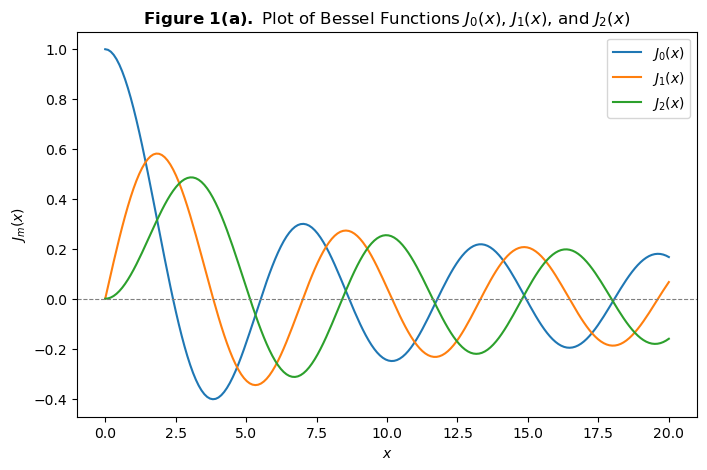

In [13]:
def J(m, x):
    N = 1000
    a = 0.0
    b = np.pi 

    # Applying 1/3 Simpson's Rule 
    if N % 2 == 0:
        N += 1
    
    h = (b - a) / (N - 1) 

    # Setting up theta points
    theta = a + np.arange(N) * h

    # Setting up the function
    f = np.cos(m * theta - x * np.sin(theta))

    # Setting up coefficient
    cs = 2 * np.ones(N)
    cs[0] = 1
    cs[-1] = 1
    cs[1::2] = 4

    # Solving integral 
    integral = (1/3) * h * np.sum(cs * f) 
    return (1/np.pi) * integral 

# Plotting values 
xvals = np.linspace(0, 20, 200)
m_vals = [0, 1, 2]

fig, ax = plt.subplots(figsize=(8,5))
for m in m_vals:
    yvals = [J(m,x) for x in xvals]
    ax.plot(xvals, yvals, label=f"$J_{m}(x)$")

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title(r"$\bf{Figure\ 1(a).}$ Plot of Bessel Functions $J_0(x)$, $J_1(x)$, and $J_2(x)$")
plt.xlabel("$x$")
plt.ylabel("$J_m(x)$")
plt.legend()
plt.grid(False)
plt.show()   

### Part B

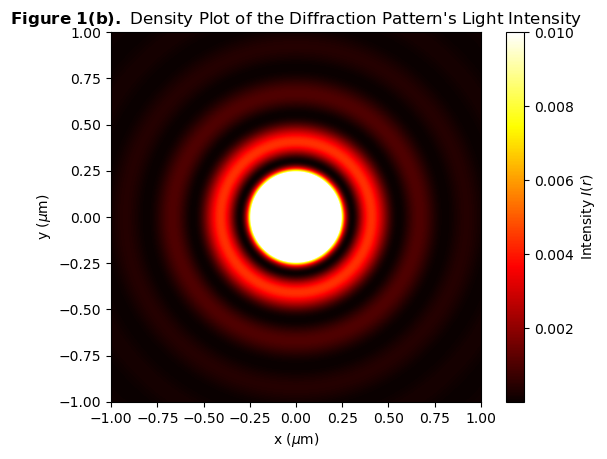

In [29]:
# Defining variables
lam = 500/1000 # Convert from nm to um
k = 2 * np.pi / lam

# Setting up coordinate grid 
r = 1.0 # this is the radius
points = 400 
x = np.linspace(-r, r, points) # 1D array representing the straight line of coordinates
y = np.linspace(-r, r, points) 
X, Y = np.meshgrid(x, y) # Uses 1D array to create a 2D array like a grid 
R = np.sqrt(X**2 + Y**2) # Calculating radial distance in 2D grid 

# Evaluating the Bessel function one point at a time
kr = k * R
I = np.zeros((points, points)) # empty 2D array to store the intensity

# Considering limits of J_1(x)/x as x approaches 0 --> yields to 1/2
for i in range(points):
    for j in range(points):
        if kr[i, j] == 0:
            frac = 0.5 
        else:
            frac = J(1, kr[i, j]) / kr[i, j]
        I[i, j] = frac**2

# Plotting the density plot 
plt.figure()
plt.imshow(I, vmax=0.01, extent=[-r, r, -r, r])
plt.xlabel(r"x ($\mu$m)")
plt.ylabel(r"y ($\mu$m)")
plt.title(r"$\bf{{Figure\ 1(b).}}$ Density Plot of the Diffraction Pattern's Light Intensity")
plt.hot()
plt.colorbar(label="Intensity $I(r)$")
plt.show()

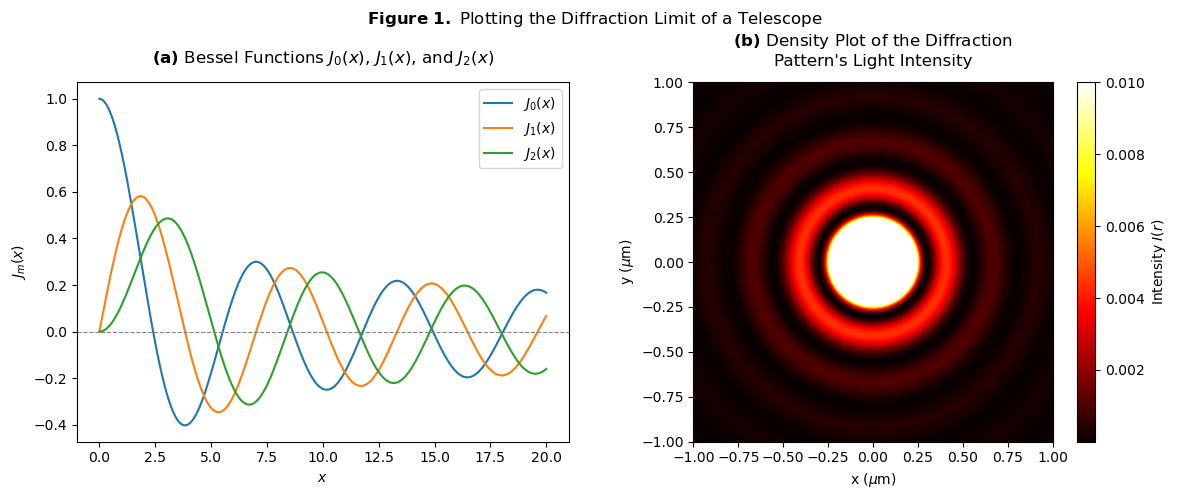

In [31]:
# Plotting them into 1x2 subplots 
fig, ax = plt.subplots(1, 2, figsize=(12,5))

for m in m_vals:
    yvals = [J(m,x) for x in xvals]
    ax[0].plot(xvals, yvals, label=f"$J_{m}(x)$")
    
ax[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax[0].set_title(r"$\bf{(a)}$ Bessel Functions $J_0(x)$, $J_1(x)$, and $J_2(x)$", fontsize=12, pad=14)
ax[0].set_xlabel("$x$")
ax[0].set_ylabel("$J_m(x)$")
ax[0].legend() 
ax[0].grid(False)

im = ax[1].imshow(I, vmax=0.01, extent=[-r, r, -r, r], cmap='hot', origin='lower')
fig.colorbar(im, ax=ax[1], label="Intensity $I(r)$")
ax[1].set_xlabel(r"x ($\mu$m)")
ax[1].set_ylabel(r"y ($\mu$m)")
ax[1].set_title(r"$\bf{(b)}$ Density Plot of the Diffraction" + "\n" "Pattern's Light Intensity", fontsize=12, pad=12)
ax[1].grid(False)

plt.suptitle(r"$\bf{Figure\ 1.}$ Plotting the Diffraction Limit of a Telescope", fontsize=12)
plt.tight_layout()
plt.savefig("prob_1.png", dpi=150)
plt.show()

Report discussion: Explain the figure

Figure 1(a) shows the Bessel functions $J_0$, $J_1$, and $J_2$ as a function of $x$ where $x \in [0, 20]$, computed via 1/3 Simpson's rule integration. The plot shows us that at $x=0$, $J_0$ is 1.0, whereas $J_1$ and $J_2$ are 0, and higher-order functions reach their first peaks/zeros progressively further to the right along $x$, and as the $x$ values increase, the functions oscillate with a gradually decreasing amplitude and non-uniform spacing between zeros or extrema. Meanwhile, Figure 1(b) shows a 2D density plot of the light intensity across a  $2\,\mu\text{m} \times 2\,\mu\text{m}$ region for wavelength $\lambda = 0.5\,\mu\text{m}$, clamped at $\mathrm{vmax} = 0.01$. It also shows an airy-disk pattern with concentric circular bright and dark rings (zeros of $J_1$) around the center due to radial symmetry, and with the vmax value, everything above it saturates at the brightest end of the hot colormap, which brings out the faint outer diffraction rings that would otherwise be drowned out. 

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [1,5]. $ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$ Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$



Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

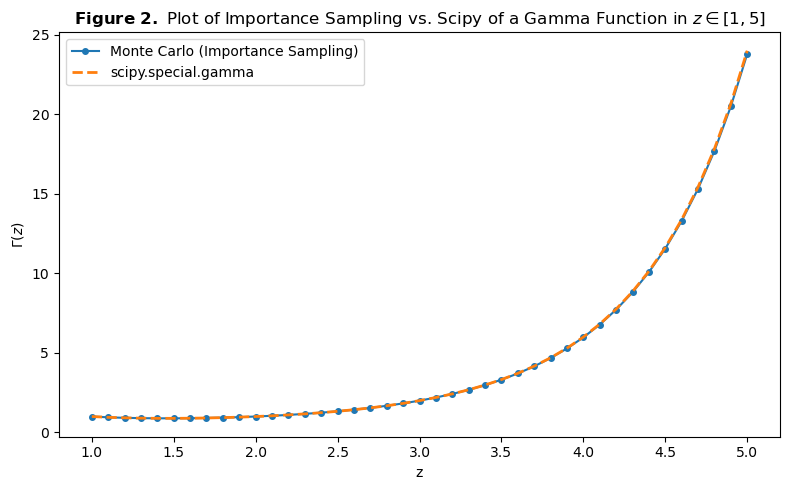

In [8]:
# Setting parameters
n = 100_100
seed = 314159

def stats(fs):
    n = fs.size
    fbar = np.sum(fs)/n
    fsq = np.sum(fs**2)/n
    varfbar = (fsq - fbar**2)/(n-1)
    return fbar, np.sqrt(varfbar)

def gamma_montecarlo(z, n=n, seed=seed):
    np.random.seed(seed)
    u = np.random.uniform(0.0, 1.0, n) # Uniform random numbers 

    t = -np.log(np.maximum(1.0 - u, 1e-15)) # Solving for t, clipping at 1e-15 to avoid -ln(0)

    g = t ** (z - 1.0) # Solving for g(x), considering that it is f(x) / p(x)

    return stats(g)

if __name__ == "__main__":
    z_vals = np.linspace(1.0, 5.0, 41) # Considering that z is in [1,5]
    mc_vals = np.empty_like(z_vals) # Monte Carlo values
    mc_errs = np.empty_like(z_vals) # Monte Carlo errors 

    for i, z in enumerate(z_vals):
        mc_vals[i], mc_errs[i] = gamma_montecarlo(z, n=n)

    exact_vals = gamma(z_vals)

    # Plotting
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(z_vals, mc_vals, "o-", markersize=4, label="Monte Carlo (Importance Sampling)")
    ax.plot(z_vals, exact_vals, "--", linewidth=2, label="scipy.special.gamma")
    ax.set_xlabel("z")
    ax.set_ylabel(r"$\Gamma(z)$")
    ax.set_title(r"$\bf{Figure\ 2.}$ Plot of Importance Sampling vs. Scipy of a Gamma Function in $z \in [1, 5]$")
    ax.legend()

    plt.grid(False)
    plt.tight_layout()
    plt.savefig("prob_2.png", dpi=150)
    plt.show() 
    

Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

Exercise 11 used both uniform and linear-density importance (else) sampling over a finite interval $[a, b]$ with a $(b - a)$ scaling factor, while this exercise solely uses exponential importance sampling without $(b - a)$ scaling, with a semi-infinite interval $[0, \infty]$. Also, instead of estimating one fixed integral at a time, this exercise evaluates $\Gamma(z)$ across a range of $z$ values in $[1,5]$ for comparison against scipy.special.gamma. When applying Monte Carlo with importance sampling, we should be careful with our choice of a normalized proposal density $p(t)$ that stays strictly positive and does not decay faster than the integrand's tails to avoid high variance and instability. Additionally, we should also be careful when reusing the same seed across sweeps or runs, as fixing the same seed inside the gamma_montecarlo across all $z$ values in z_vals keeps results reproducible and correlated across the sweep.

### Code Summary

My code for Problem 1 implements Bessel functions $J_m(x)$ using Simpson's 1/3 rule over $[0, \pi]$ to plot $J_0$, $J_1$, and $J_2$ and generate a 2D circular diffraction intensity density map on $I(r)$ with the small-argument limit handled explicitly. My code for Problem 2 estimates the Gamma function $\Gamma(z)$ across $z \in [1,5]$ via importance sampling using exponential inverse-transform samples comparing the results against scipy.special.gamma. Both rely on NumPy arrays and Matplotlib visualizations. 